In [1]:
import sys
import os
import joblib
import pandas as pd
from sklearn.preprocessing import StandardScaler
sys.path.append(os.path.abspath(".."))
from utils.base_model import *

In [2]:
data = joblib.load("../artifacts/processed_data.pkl")
X_train = data["X_train_res"]
y_train = data["y_train_res"]
X_val   = data["X_val_scaled"]
y_val   = data["y_val"]
X_test  = data["X_test_scaled"]
y_test  = data["y_test"]
feature_names = data["feature_names"]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (42732, 16) | Val: (4526, 16) | Test: (4401, 16)


In [3]:
X_train.head()

,active_days,total_secs,num_100,num_25,num_unq,city,age,registered_via,tx_count,total_paid,auto_renew_ratio,cancel_count,decay_ratio,skip_ratio,avg_secs_per_active_day,is_age_missing
0,-1.149705,-0.527290,-0.572306,-0.479919,-0.438088,0.716815,-1.866253,-1.10768,0.372122,-1.174205,0.372122,-0.071106,-0.694715,0.068430,-0.078509,-1.015762
1,-0.170465,0.556916,0.597731,-0.386555,0.338968,-0.205208,-1.064623,1.10787,0.372122,-1.174205,0.372122,-0.071106,-0.546822,-0.972251,0.729908,-1.015762
2,-1.345553,-1.304132,-1.312402,-1.472215,-1.500905,-0.819889,-0.102668,-1.10768,-2.687293,-1.174205,-2.687293,-0.071106,-0.694641,-0.240305,-0.834331,0.984483
3,1.004623,0.489830,0.547791,0.173391,0.533603,1.024156,-0.583646,-1.55079,0.372122,0.851640,0.372122,-0.071106,-0.306810,-0.670627,0.078273,-1.015762
4,0.025383,0.254716,0.196397,0.632591,0.319580,-0.819889,-0.102668,0.22165,0.372122,0.851640,0.372122,-0.071106,-0.183077,0.379850,0.087665,0.984483


# Logistic Regression

TRAIN

In [4]:
log_model = train_model(X_train, y_train, model_type="logistic", C=0.5, max_iter=600)


>>> Đang train mô hình: LOGISTIC...


c:\Users\jason\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


>>> Đã train xong: LOGISTIC!


VALIDATION

In [5]:
val_proba_log = predict_proba_pos(log_model, X_val)
best_th_log, th_df_log = find_best_threshold(y_val, val_proba_log, metric="f1")

Best threshold theo f1: 0.77


EVAL

In [6]:
test_proba_log = predict_proba_pos(log_model, X_test)
res_log = evaluate_model(y_test, test_proba_log, threshold=best_th_log, title="LOGISTIC REGRESSION")

===== LOGISTIC REGRESSION (THRESHOLD = 0.77) =====
Accuracy : 0.8573
Precision: 0.8476
Recall   : 0.9393
F1-score : 0.8911
ROC-AUC  : 0.8999
PR-AUC   : 0.9181

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.72      0.79      1666
           1       0.85      0.94      0.89      2735

    accuracy                           0.86      4401
   macro avg       0.86      0.83      0.84      4401
weighted avg       0.86      0.86      0.85      4401



PLOT

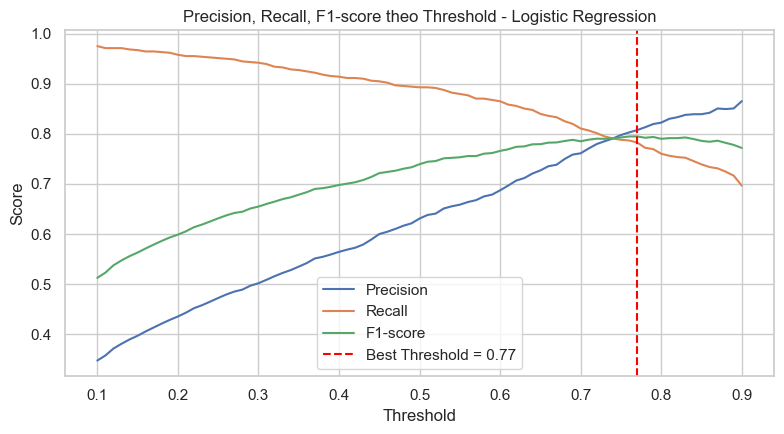

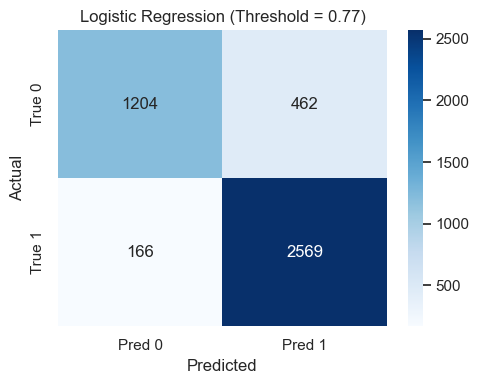

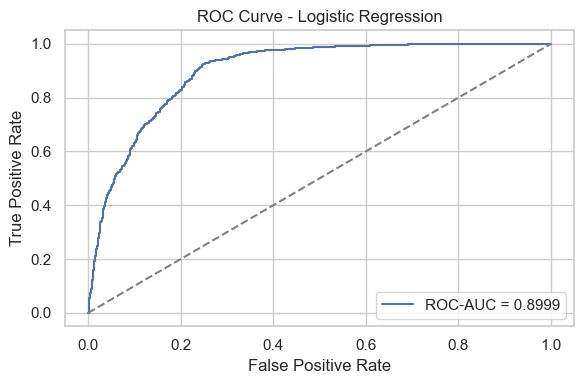

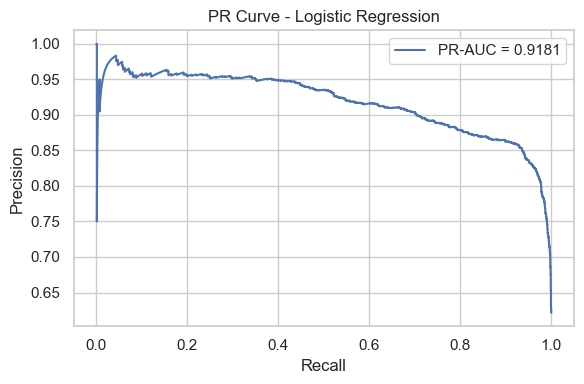

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


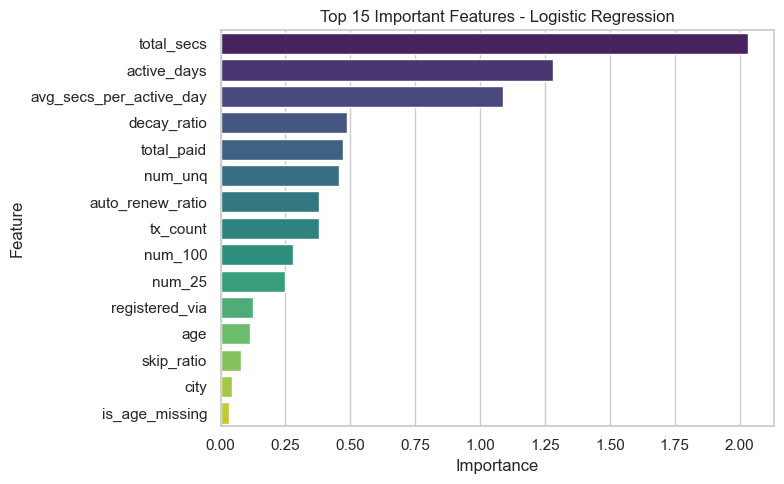

,feature,importance
1,total_secs,2.031218
0,active_days,1.280672
14,avg_secs_per_active_day,1.087353
12,decay_ratio,0.488114
9,total_paid,0.472478
4,num_unq,0.457526
10,auto_renew_ratio,0.380639
8,tx_count,0.380639
2,num_100,0.279417
3,num_25,0.248764


In [7]:
plot_threshold_metrics(th_df_log, best_th_log, title="Logistic Regression")
plot_confusion_matrix_custom(y_test, test_proba_log, threshold=best_th_log, title="Logistic Regression")
plot_roc_curve_custom(y_test, test_proba_log, title="ROC Curve - Logistic Regression")
plot_pr_curve_custom(y_test, test_proba_log, title="PR Curve - Logistic Regression")
plot_feature_importance(log_model, feature_names, title="Logistic Regression")

SAVE

In [8]:
save_model(log_model, "../artifacts/logistic_model.pkl", "../artifacts/logistic_info.pkl", best_th_log, feature_names, model_type="logistic_regression")

Đã lưu model: ../artifacts/logistic_model.pkl
Đã lưu model info: ../artifacts/logistic_info.pkl


# Mock test

In [ ]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_log 
pred_proba = predict_proba_pos(log_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])

# DECISION TREE

TRAIN

In [10]:
dt_model = train_model(X_train, y_train, model_type="decision_tree", max_depth=8, min_samples_split=20)


>>> Đang train mô hình: DECISION_TREE...
>>> Đã train xong: DECISION_TREE!


VALIDATION

In [11]:
val_proba_dt = predict_proba_pos(dt_model, X_val)
best_th_dt, th_df_dt = find_best_threshold(y_val, val_proba_dt, metric="f1")

Best threshold theo f1: 0.83


EVAL

In [12]:
test_proba_dt = predict_proba_pos(dt_model, X_test)
res_dt = evaluate_model(y_test, test_proba_dt, threshold=best_th_dt, title="DECISION TREE")

===== DECISION TREE (THRESHOLD = 0.83) =====
Accuracy : 0.8571
Precision: 0.8674
Recall   : 0.909
F1-score : 0.8877
ROC-AUC  : 0.9144
PR-AUC   : 0.9264

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.77      0.80      1666
           1       0.87      0.91      0.89      2735

    accuracy                           0.86      4401
   macro avg       0.85      0.84      0.85      4401
weighted avg       0.86      0.86      0.86      4401



PLOT

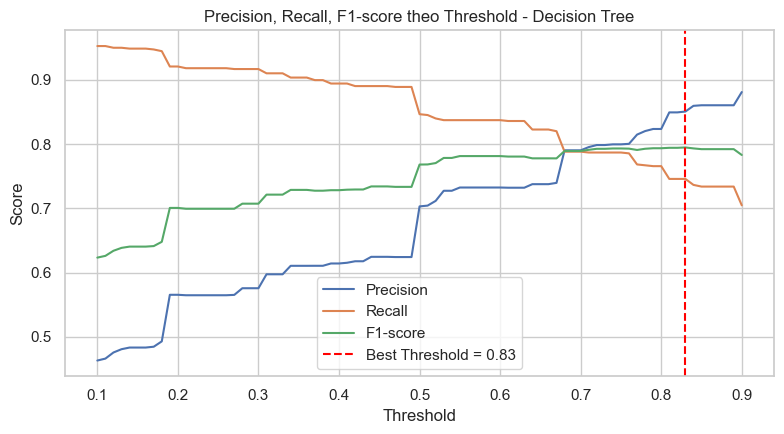

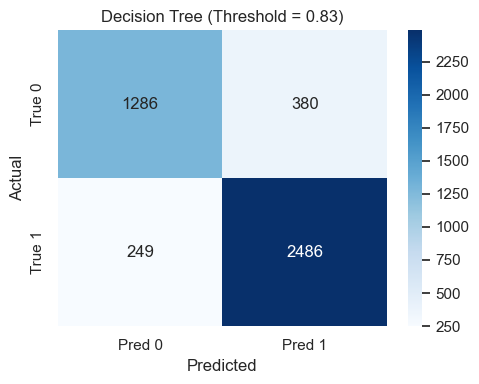

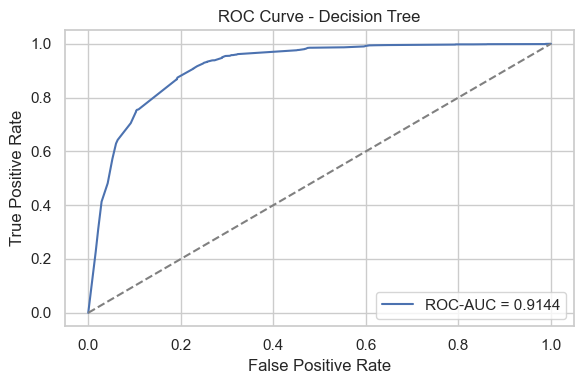

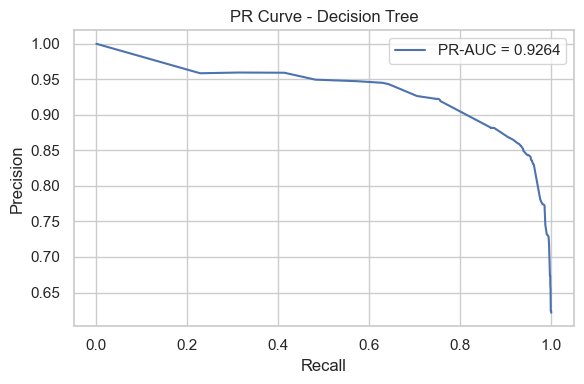

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


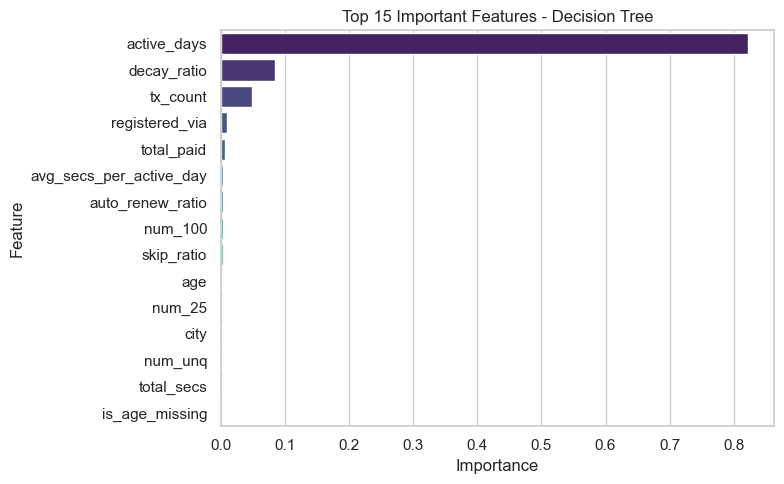

,feature,importance
0,active_days,0.821512
12,decay_ratio,0.085336
8,tx_count,0.048522
7,registered_via,0.009724
9,total_paid,0.007089
14,avg_secs_per_active_day,0.004071
10,auto_renew_ratio,0.003801
2,num_100,0.003799
13,skip_ratio,0.003517
6,age,0.003037


In [13]:
plot_threshold_metrics(th_df_dt, best_th_dt, title="Decision Tree")
plot_confusion_matrix_custom(y_test, test_proba_dt, threshold=best_th_dt, title="Decision Tree")
plot_roc_curve_custom(y_test, test_proba_dt, title="ROC Curve - Decision Tree")
plot_pr_curve_custom(y_test, test_proba_dt, title="PR Curve - Decision Tree")
plot_feature_importance(dt_model, feature_names, title="Decision Tree")

SAVE

In [14]:
save_model(dt_model, "../artifacts/decision_tree_model.pkl", "../artifacts/decision_tree_info.pkl", best_th_dt, feature_names, model_type="decision_tree")

Đã lưu model: ../artifacts/decision_tree_model.pkl
Đã lưu model info: ../artifacts/decision_tree_info.pkl


In [46]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_dt
pred_proba = predict_proba_pos(dt_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])


===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====


,Status,Churn_Probability,active_days,total_secs,num_100,num_25,num_unq
0,Stay,0.0015,30,250000,0,0.05,1
1,Leave,1.0000,2,5000,1,0.85,0
2,Stay,0.0235,15,120000,0,0.20,1
3,Stay,0.5857,1,1200,2,0.95,0
4,Stay,0.0174,28,300000,0,0.02,1


# RANDOM FOREST

TRAIN

In [15]:
rf_model = train_model(X_train, y_train, model_type="random_forest", n_estimators=200, max_depth=12)


>>> Đang train mô hình: RANDOM_FOREST...
>>> Đã train xong: RANDOM_FOREST!


VALIDATION

In [16]:
val_proba_rf = predict_proba_pos(rf_model, X_val)
best_th_rf, th_df_rf = find_best_threshold(y_val, val_proba_rf, metric="f1")

Best threshold theo f1: 0.62


EVAL

In [17]:
test_proba_rf = predict_proba_pos(rf_model, X_test)
res_rf = evaluate_model(y_test, test_proba_rf, threshold=best_th_rf, title="RANDOM FOREST")

===== RANDOM FOREST (THRESHOLD = 0.62) =====
Accuracy : 0.8646
Precision: 0.8444
Recall   : 0.9587
F1-score : 0.8979
ROC-AUC  : 0.9208
PR-AUC   : 0.9374

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1666
           1       0.84      0.96      0.90      2735

    accuracy                           0.86      4401
   macro avg       0.88      0.83      0.85      4401
weighted avg       0.87      0.86      0.86      4401



PLOT

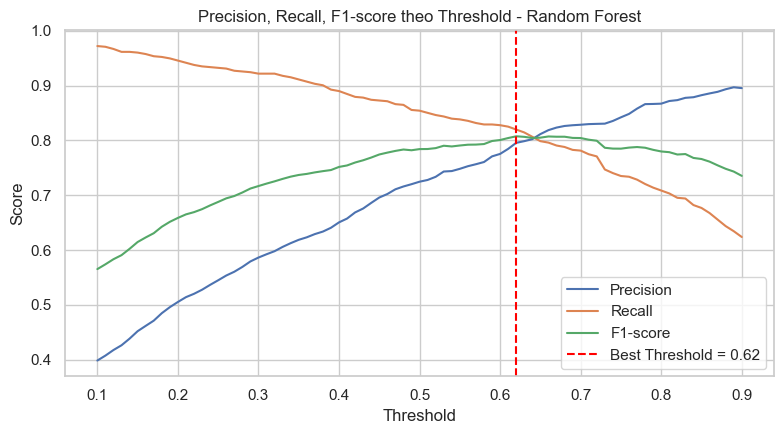

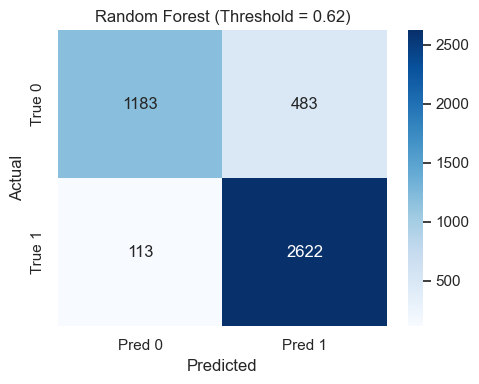

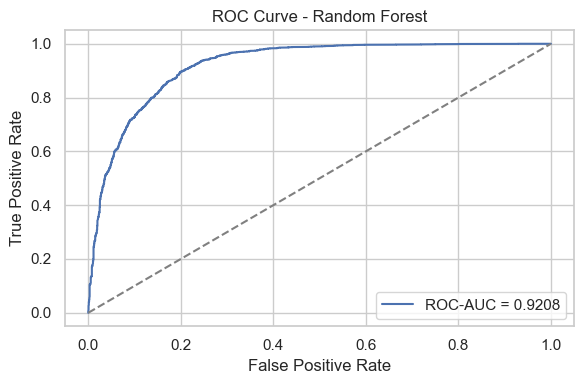

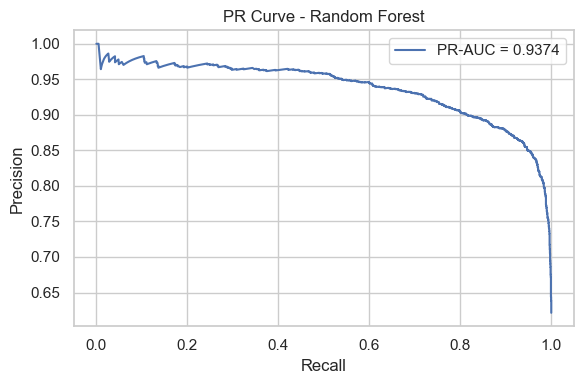

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


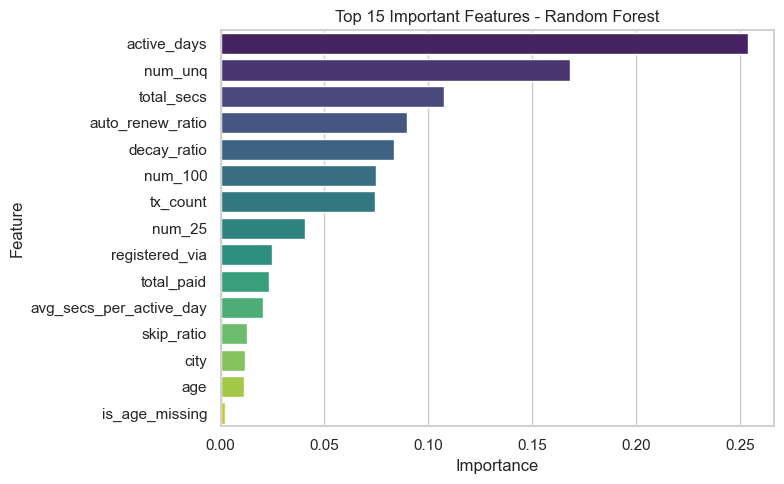

,feature,importance
0,active_days,0.253743
4,num_unq,0.168344
1,total_secs,0.107430
10,auto_renew_ratio,0.089912
12,decay_ratio,0.083586
2,num_100,0.074905
8,tx_count,0.074490
3,num_25,0.040655
7,registered_via,0.024681
9,total_paid,0.023152


In [18]:
plot_threshold_metrics(th_df_rf, best_th_rf, title="Random Forest")
plot_confusion_matrix_custom(y_test, test_proba_rf, threshold=best_th_rf, title="Random Forest")
plot_roc_curve_custom(y_test, test_proba_rf, title="ROC Curve - Random Forest")
plot_pr_curve_custom(y_test, test_proba_rf, title="PR Curve - Random Forest")
plot_feature_importance(rf_model, feature_names, title="Random Forest")

SAVE

In [19]:
save_model(rf_model, "../artifacts/random_forest_model.pkl", "../artifacts/random_forest_info.pkl",
           best_th_rf, feature_names, model_type="random_forest")

Đã lưu model: ../artifacts/random_forest_model.pkl
Đã lưu model info: ../artifacts/random_forest_info.pkl


In [47]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_rf 
pred_proba = predict_proba_pos(rf_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])


===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====


,Status,Churn_Probability,active_days,total_secs,num_100,num_25,num_unq
0,Stay,0.2980,30,250000,0,0.05,1
1,Stay,0.6122,2,5000,1,0.85,0
2,Stay,0.3437,15,120000,0,0.20,1
3,Leave,0.6994,1,1200,2,0.95,0
4,Stay,0.2888,28,300000,0,0.02,1


# XG BOOST

TRAIN

In [20]:
scale_pos_weight = cal_scale_pos_weight(y_train)

Negative (0): 21,366 | Positive (1): 21,366
scale_pos_weight: 1.00


In [21]:
xgb_model = train_model(
    X_train, y_train,
    model_type="xgboost",
    scale_pos_weight=scale_pos_weight,
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03
)


>>> Đang train mô hình: XGBOOST...
>>> Đã train xong: XGBOOST!


VALIDATION

In [22]:
val_proba_xgb = predict_proba_pos(xgb_model, X_val)
best_th_xgb, th_df_xgb = find_best_threshold(y_val, val_proba_xgb, metric="f1")

Best threshold theo f1: 0.65


EVAL

In [23]:
test_proba_xgb = predict_proba_pos(xgb_model, X_test)
res_xgb = evaluate_model(y_test, test_proba_xgb, threshold=best_th_xgb, title="XGBOOST")

===== XGBOOST (THRESHOLD = 0.65) =====
Accuracy : 0.8675
Precision: 0.8582
Recall   : 0.9426
F1-score : 0.8984
ROC-AUC  : 0.9246
PR-AUC   : 0.9405

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1666
           1       0.86      0.94      0.90      2735

    accuracy                           0.87      4401
   macro avg       0.87      0.84      0.85      4401
weighted avg       0.87      0.87      0.86      4401



PLOT

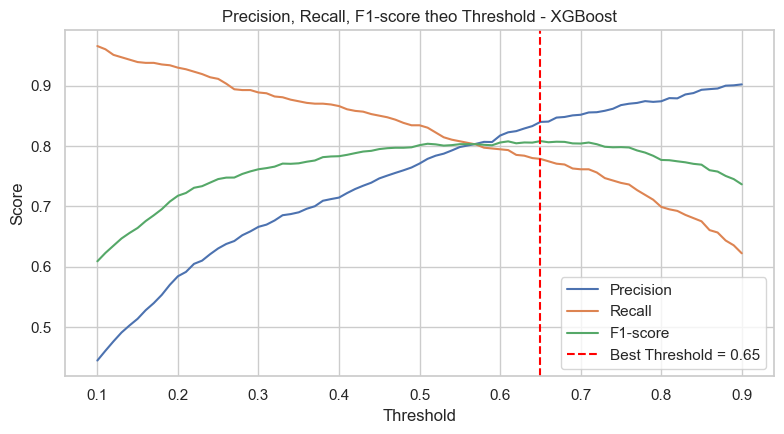

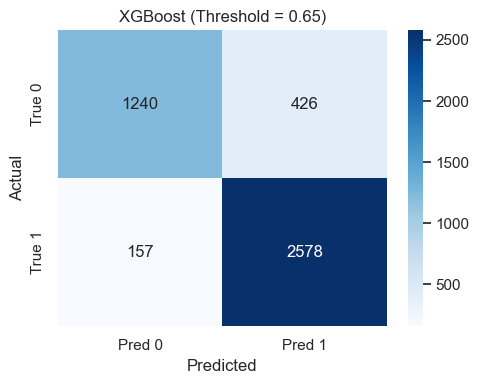

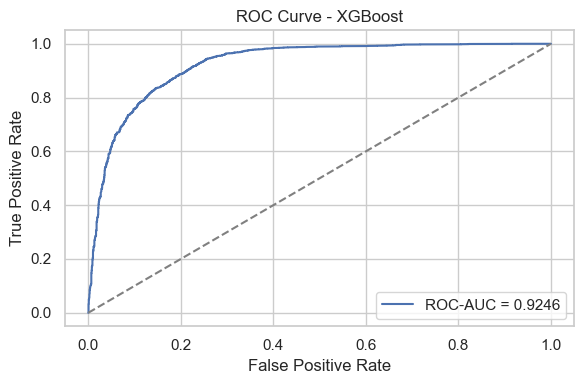

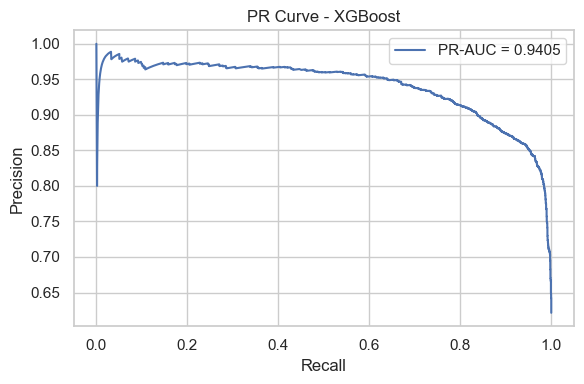

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


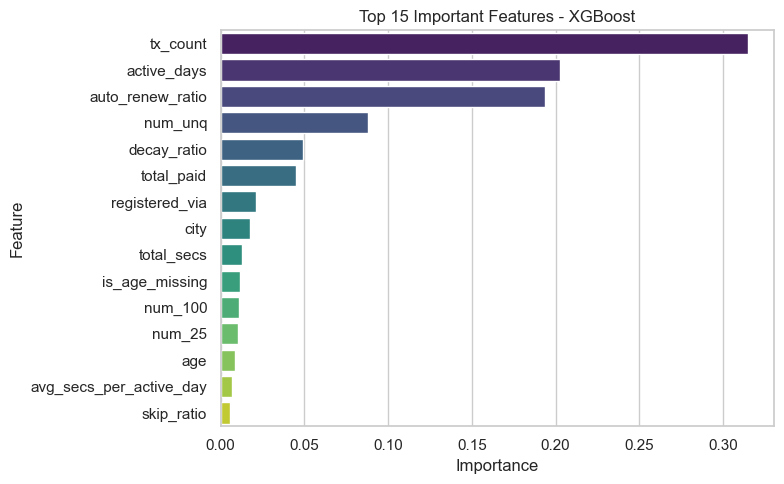

,feature,importance
8,tx_count,0.314711
0,active_days,0.202678
10,auto_renew_ratio,0.193554
4,num_unq,0.088249
12,decay_ratio,0.049500
9,total_paid,0.044967
7,registered_via,0.021280
5,city,0.017867
1,total_secs,0.012934
15,is_age_missing,0.011398


In [24]:
plot_threshold_metrics(th_df_xgb, best_th_xgb, title="XGBoost")
plot_confusion_matrix_custom(y_test, test_proba_xgb, threshold=best_th_xgb, title="XGBoost")
plot_roc_curve_custom(y_test, test_proba_xgb, title="ROC Curve - XGBoost")
plot_pr_curve_custom(y_test, test_proba_xgb, title="PR Curve - XGBoost")
plot_feature_importance(xgb_model, feature_names, title="XGBoost")

SAVE

In [25]:
save_model(xgb_model, "../artifacts/xgboost_model.pkl", "../artifacts/xgboost_info.pkl",
           best_th_xgb, feature_names, model_type="xgboost", scale_pos_weight=scale_pos_weight)

Đã lưu model: ../artifacts/xgboost_model.pkl
Đã lưu model info: ../artifacts/xgboost_info.pkl


In [53]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_xgb 
pred_proba = predict_proba_pos(xgb_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])


===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====


,Status,Churn_Probability,active_days,total_secs,num_100,num_25,num_unq
0,Stay,0.1279,30,250000,0,0.05,1
1,Leave,0.9985,2,5000,1,0.85,0
2,Leave,0.9087,15,120000,0,0.20,1
3,Leave,0.9992,1,1200,2,0.95,0
4,Leave,0.6184,28,300000,0,0.02,1


# COMPARISON

In [26]:
comparison_df = pd.DataFrame([
    {"Model": "Logistic Regression", **res_log},
    {"Model": "Decision Tree", **res_dt},
    {"Model": "Random Forest", **res_rf},
    {"Model": "XGBoost", **res_xgb},
]).sort_values(by="F1-score Class 1", ascending=False)

display(comparison_df)

,Model,Best Threshold,ROC-AUC,PR-AUC,Accuracy,Precision Class 1,Recall Class 1,F1-score Class 1
3,XGBoost,0.65,0.9246,0.9405,0.8675,0.8582,0.9426,0.8984
2,Random Forest,0.62,0.9208,0.9374,0.8646,0.8444,0.9587,0.8979
0,Logistic Regression,0.77,0.8999,0.9181,0.8573,0.8476,0.9393,0.8911
1,Decision Tree,0.83,0.9144,0.9264,0.8571,0.8674,0.9090,0.8877


In [33]:
from PIL import Image, ImageOps, ImageDraw

# Đọc hai ảnh
img1 = Image.open("../rf.png").convert("RGB")
img2 = Image.open("../xgb.png").convert("RGB")

# Chuẩn hóa kích thước
size = (900, 550)
img1 = ImageOps.contain(img1, size)
img2 = ImageOps.contain(img2, size)

# Tạo nền trắng, ghép ngang
combined = Image.new("RGB", (1860, 590), "white")
combined.paste(img1, ((900-img1.width)//2, 20))
combined.paste(img2, (940+(900-img2.width)//2, 20))

# Xuất hình với chất lượng cao
combined.save("Hinh_3_22.png", dpi=(300, 300))


In [32]:
combined.show()